## 1. Import Libraries

In [4]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score

2. Connect to Duckdb

In [5]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PARQUET = ROOT / "data/processed/essays.parquet"

con = duckdb.connect()
df = con.sql(f"select * from '{PARQUET}'").df()
df.shape

(20243, 7)

In [6]:
#read a few labels to confirm that label 1 is AI 
for label in (0, 1):
    print(f"--- label {label}")
    for t in df[df.label == label].sample(3, random_state=0).text:
        print(t[:300].replace("\n", " "), "\n")


--- label 0
Phones and Driving Essay  Many people use their cellphone daily, for some their cellphone is a part of their life, it helps them to communicate with others and ;their phone keeps them connected to news and events all around the world. On the contrary phones may be a distraction when a driver is behi 

Do you think that seeking more opinions can help you to make a better choice? If you get multiple opinions, you will have the capability to make better choices throughout your life. I believe that seeking more opinions is a better option because you can find many different points of view, you can ge 

The face on Mars wasn't created by aliens. The way I know this is that our spacecraft around the planet Mars took pictures and concluded that it was just a martian Mesa or just a natural landform. We unveiled the picture to the public to see what they see it has a illusion of nose,mouth, and some ey 

--- label 1
Introduction: Hey there! Have you heard about the Face on Mars? Som

In [7]:
con.sql(f"""
    select split, count(*) as rows, sum(label) as ai, round(avg(label), 3) as ai_share
    from '{PARQUET}' group by split order by split
""").df()

,split,rows,ai,ai_share
0,test,3036,492.0,0.162
1,train,14171,2295.0,0.162
2,val,3036,492.0,0.162


         count   mean    std    min    25%    50%    75%     max
label                                                           
0      16964.0  404.0  174.0  150.0  273.0  378.0  498.0  1656.0
1       3279.0  392.0   99.0   50.0  321.0  380.0  448.0   766.0


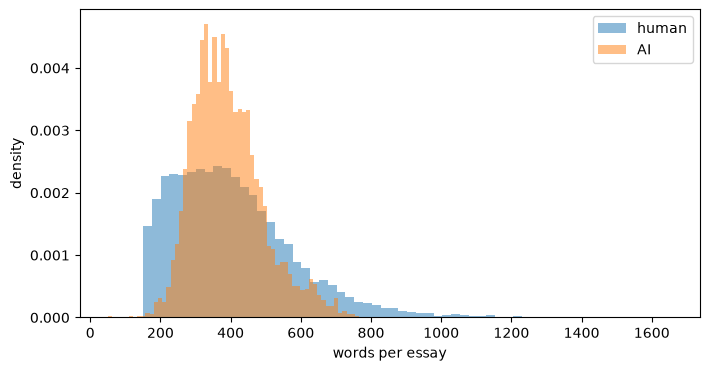

In [8]:
print(df.groupby("label")["n_words"].describe().round(0))

fig, ax = plt.subplots(figsize=(8, 4))
for label, name in ((0, "human"), (1, "AI")):
    ax.hist(df[df.label == label]["n_words"], bins=60, alpha=.5, density=True, label=name)
ax.set_xlabel("words per essay")
ax.set_ylabel("density")
ax.legend()
plt.show()

In [14]:
import re

def style_signals(text):
    words = re.findall(r"\w+", text.lower())
    sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]
    return {
        "n_newlines": text.count("\n"),
        "avg_sentence_words": len(words) / max(len(sentences), 1),
        "unique_word_ratio": len(set(words)) / max(len(words), 1),
        "commas_per_100w": 100 * text.count(",") / max(len(words), 1)
    }

signals = df["text"].apply(style_signals).apply(pd.Series)
print(signals.assign(label=df["label"]).groupby("label").mean().round(3))

#How well does the signal seperate the classes. 0.5 is useless and 1.0 is perfect
train = df["split"] == "train"
features = signals.assign(n_words=df["n_words"])
for col in features.columns:
    auc = roc_auc_score(df[train]["label"], features[col][train])
    print(f"{col:20s} AUC on train: {auc:.3f}")

       n_newlines  avg_sentence_words  unique_word_ratio  commas_per_100w
label                                                                    
0           8.137              20.474              0.459            3.279
1          14.091              17.992              0.465            5.565
n_newlines           AUC on train: 0.831
avg_sentence_words   AUC on train: 0.416
unique_word_ratio    AUC on train: 0.487
commas_per_100w      AUC on train: 0.794
n_words              AUC on train: 0.520


In [17]:
con.sql(f"""
    select sources, count(*) as n, round(avg(label), 3) as ai_share
    from '{PARQUET}' group by sources order by n desc
""")

sourcesVARCHAR,nBIGINT,ai_shareDOUBLE
"p7,p7v2,rd1,rd2",12013,0.085
"rd1,rd2",3521,0.075
"p7,p7v2",2852,0.047
rd2,1384,1.0
"p7v2,rd1,rd2",327,1.0
p7v2,146,1.0
